# Transmisión por paralelogramos: rodilla y tobillo desde el torso

Visualiza el modelo de [`leg_transmission.py`](leg_transmission.py): la cadera sigue en accionamiento directo, y la rodilla y el tobillo se mueven desde motores dentro del torso (a la altura de la cadera) mediante paralelogramos, como en el mecanismo de referencia (MG996R).

| Paralelogramo | Lados | Qué copia |
|---|---|---|
| `knee` | manivela en eje de cadera, biela ∥ muslo, palanca fija a la tibia | orientación del motor de rodilla → tibia |
| `ankle_upper` | manivela en eje de cadera, biela ∥ muslo, brazo del balancín libre en la rodilla | orientación del motor de tobillo → balancín |
| `ankle_lower` | otro brazo del balancín, biela ∥ tibia, palanca fija al metatarso | balancín → metatarso |

Como un paralelogramo copia orientaciones, **cada motor fija el ángulo absoluto (respecto al torso) de su segmento**:

$$m_{hip} = hip, \qquad m_{knee} = hip - knee, \qquad m_{ankle} = hip - knee + ankle$$

**Convención**: la del modelo de MuJoCo `senecabot_loco.xml`, que es exactamente la de las columnas `*_joint` del CSV del ciclo de marcha (`servos/leg_actuator_angles_one_cycle.csv`, solo se lee). Cabeceo alrededor de +y, 0 = segmento colgando vertical, positivo = el segmento rota hacia atrás (la rodilla tiene eje −y, por eso entra con signo menos). Longitudes: delanteras 0.121 / 0.111 / 0.1534 m, traseras 0.166 / 0.231 / 0.148 m.

En los dibujos, el largo de manivelas (`CRANK_LENGTH` = 30 mm) y la separación entre motores (`MOTOR_SPACING` = 45 mm) son ilustrativos. Las patas izquierdas (FL, BL) son iguales a las derechas porque la marcha está simetrizada, así que solo se muestran FR y BR.

In [1]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from matplotlib.animation import FuncAnimation

import leg_transmission as lt

df = pd.read_csv(lt.CSV_PATH)
t = df["time_s"].to_numpy()
dt = float(np.median(np.diff(t)))
LEGS_SHOWN = ["fr", "br"]
joints = {leg: [df[f"{leg}_{j}_joint"].to_numpy() for j in lt.JOINTS] for leg in LEGS_SHOWN}

# Offsets de las palancas centrados para el ciclo (paralelogramos alrededor de 90 grados)
offsets = {}
for leg in LEGS_SHOWN:
    summary, offsets[leg] = lt.leg_summary(df, leg, dt)
    print(summary, end="\n\n")

Pata FR  (L = (0.121, 0.111, 0.1534) m)
  motor     centro   rango  |vel|max   directo: rango |vel|max
  hip         49.0    20.2       163             20.2      163
  knee       -61.4    20.8       220             38.9      249
  ankle       49.2    85.3       846             83.0      769
  paralelogramo   offset    angulo interno  margen
  knee              20.9     70.6 a  109.4    70.6
  ankle_upper       88.6     39.8 a  140.2    39.8
  ankle_lower      -15.9     48.5 a  131.5    48.5

Pata BR  (L = (0.166, 0.231, 0.148) m)
  motor     centro   rango  |vel|max   directo: rango |vel|max
  hip        -46.6    13.1        84             13.1       84
  knee        59.3    21.6       238             29.5      296
  ankle        6.0    54.0       422             49.2      493
  paralelogramo   offset    angulo interno  margen
  knee             -18.5     75.2 a  104.8    75.2
  ankle_upper       37.7     57.0 a  123.0    57.0
  ankle_lower      -34.7     65.4 a  114.6    65.4



## Resumen del ciclo

- **Motores**: `centro` y `rango` del ángulo que debe recorrer cada motor del torso; `|vel|max` es la velocidad pico (ciclo suavizado a 4 armónicos, como en `servos/plot_one_cycle.py`). Las columnas `directo` son lo que pediría la misma articulación con el motor montado en la pata, para comparar.
- **Paralelogramos**: `offset` es el ángulo de la palanca respecto a su segmento que centra el paralelogramo en 90°; `ángulo interno` es su rango en el ciclo y `margen` la distancia mínima a 0°/180° (paralelogramo aplanado → singular, puede invertirse).
- Referencia: un MG996R sin carga da ≈ 350 °/s a 4.8 V y ≈ 430 °/s a 6 V (0.17 / 0.14 s por 60°, hoja de datos).

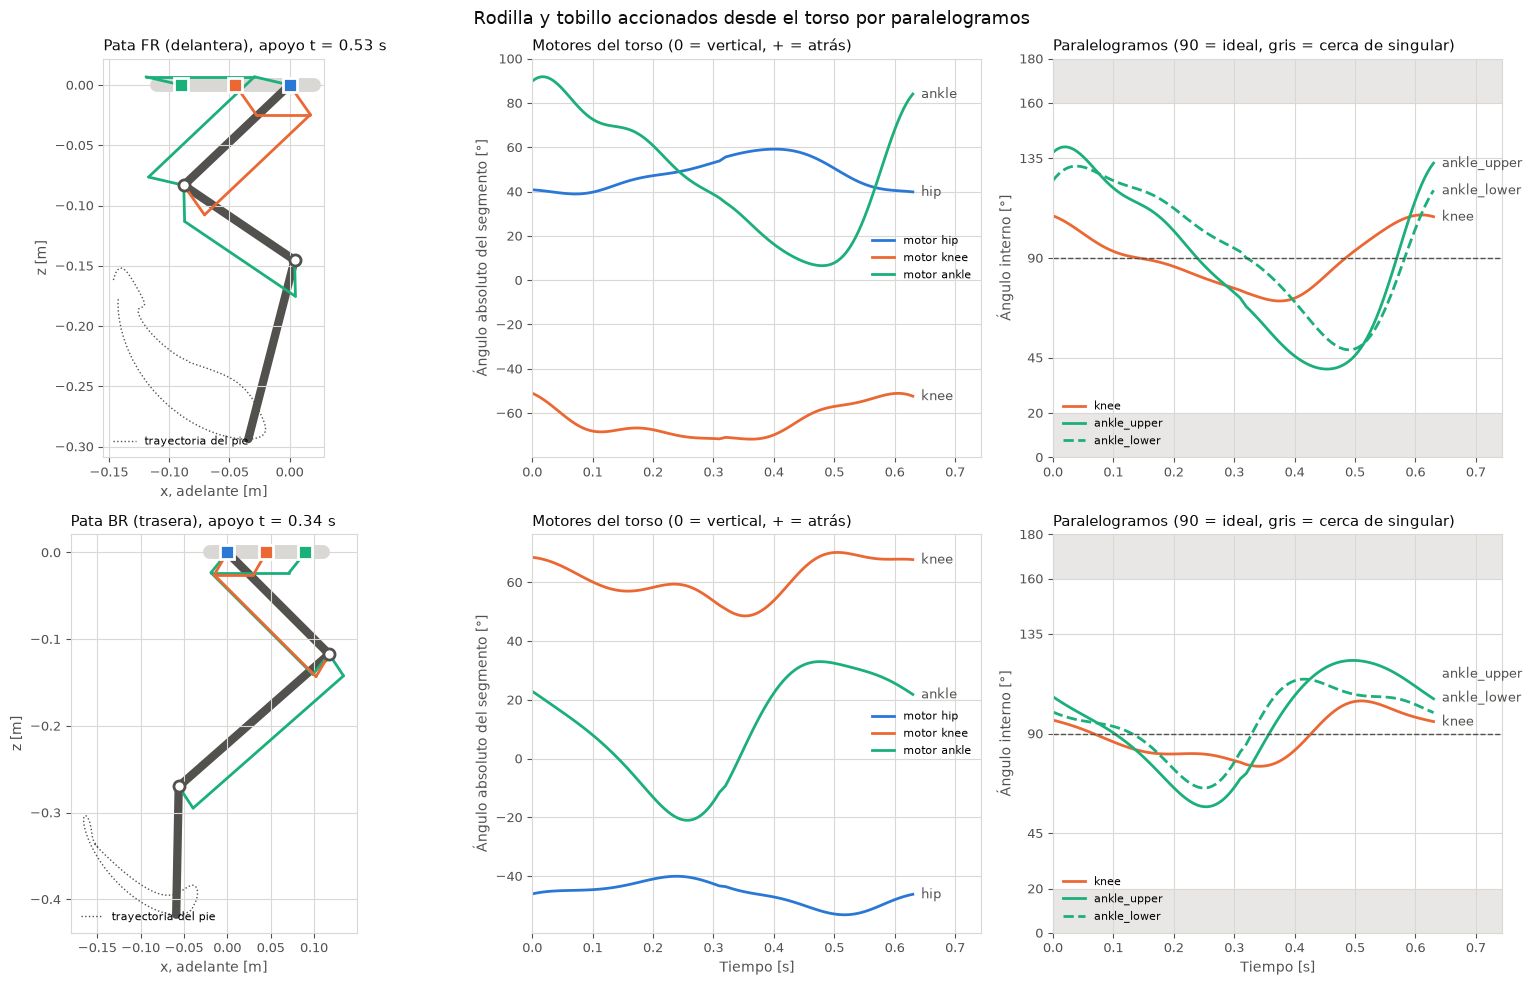

In [2]:
fig = lt.build_figure(df, offsets)
plt.show()

## Animación del ciclo

Mecanismo completo de FR y BR a lo largo de un ciclo (0.63 s), en cámara lenta (`ANIM_FPS` cuadros por segundo, 1 de cada `ANIM_STEP` muestras del CSV a 200 Hz). Naranja = transmisión de la rodilla, verde = transmisión del tobillo; los cuadrados son los ejes de los motores (azul = cadera).

In [3]:
ANIM_STEP = 3
ANIM_FPS = 15
frames = range(0, len(df), ANIM_STEP)
foot_paths = {leg: lt.leg_points(leg, *joints[leg])[2] for leg in LEGS_SHOWN}


def cycle_limits(leg, margin=0.04):
    # Caja fija que contiene la pata en todo el ciclo y los motores del torso.
    pts = np.vstack([np.vstack(lt.leg_points(leg, *joints[leg])), [[0.0, 0.0]],
                     [[(-2 if leg.startswith("f") else 2) * lt.MOTOR_SPACING, 0.0]]])
    lo, hi = pts.min(axis=0) - margin, pts.max(axis=0) + margin
    return (lo[0], hi[0]), (lo[1], hi[1])


fig_anim, axs_anim = plt.subplots(1, 2, figsize=(10, 5.5), dpi=72)


def update(i):
    for ax, leg in zip(axs_anim, LEGS_SHOWN):
        ax.clear()
        q = [x[i] for x in joints[leg]]
        m = lt.joint_to_motor(*q)
        ax.plot(*foot_paths[leg].T, color=lt.INK_MUTED, linewidth=1, linestyle=":")
        lt.draw_mechanism(ax, leg, *q, offsets[leg])
        xlim, ylim = cycle_limits(leg)
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        ax.set_aspect("equal")
        ax.set_xlabel("x, adelante [m]", color=lt.INK_MUTED)
        lt._style_axis(ax, f"{leg.upper()}  t = {t[i]:.3f} s\nmotores: hip {m[0]:.0f}°  knee {m[1]:.0f}°  ankle {m[2]:.0f}°")
    return []


anim = FuncAnimation(fig_anim, update, frames=frames, interval=1000 / ANIM_FPS)
html_anim = HTML(anim.to_jshtml(fps=ANIM_FPS))
plt.close(fig_anim)
html_anim

## Explorador interactivo (requiere kernel activo)

Los sliders son los **motores del torso** (ángulo absoluto de cada segmento). Al mover solo el motor de cadera el muslo gira y la tibia y el metatarso se trasladan **sin cambiar de orientación**: ese es el desacople que da el paralelogramo. Debajo se listan los ángulos articulares resultantes (convención del CSV) y el ángulo interno de cada paralelogramo; se marcan con ⚠ los que quedan a menos de `WARN_MARGIN` grados de aplanarse y las articulaciones fuera del rango del modelo de MuJoCo. El botón vuelve a la pose de apoyo (pie en su punto más bajo del ciclo).

In [4]:
WARN_MARGIN = 20  # grados
# Rangos articulares de senecabot_loco.xml (grados)
JOINT_LIMITS = {
    "fr": {"hip": (25, 105), "knee": (34, 150), "ankle": (0, 160)},
    "br": {"hip": (-105, -40), "knee": (-140, -40), "ankle": (-85, 0)},
}
stance = {leg: int(np.argmin(foot_paths[leg][:, 1])) for leg in LEGS_SHOWN}


def stance_motors(leg):
    return lt.joint_to_motor(*(x[stance[leg]] for x in joints[leg]))


leg_dropdown = widgets.Dropdown(options=[("FR (delantera)", "fr"), ("BR (trasera)", "br")], value="fr", description="Pata:")
motor_sliders = {
    joint: widgets.FloatSlider(min=-150, max=150, step=1, description=f"motor {joint} [°]",
                               continuous_update=False, style={"description_width": "110px"},
                               layout=widgets.Layout(width="480px"))
    for joint in lt.JOINTS
}
reset_button = widgets.Button(description="Pose de apoyo")


def reset_pose(_=None):
    for slider, value in zip(motor_sliders.values(), stance_motors(leg_dropdown.value)):
        slider.value = round(float(value))


def explore(leg, hip, knee, ankle):
    # hip/knee/ankle aqui son los angulos de MOTOR (absolutos)
    q = lt.motor_to_joint(hip, knee, ankle)
    reach = sum(lt.leg_lengths(leg)) + 0.03
    fig, ax = plt.subplots(figsize=(7, 5.5))
    ax.plot(*foot_paths[leg].T, color=lt.INK_MUTED, linewidth=1, linestyle=":", label="pie en la marcha")
    lt.draw_mechanism(ax, leg, *q, offsets[leg])
    ax.set_xlim(-0.8 * reach, 0.8 * reach)
    ax.set_ylim(-reach, 0.08)
    ax.set_aspect("equal")
    ax.set_xlabel("x, adelante [m]", color=lt.INK_MUTED)
    ax.set_ylabel("z [m]", color=lt.INK_MUTED)
    ax.legend(loc="lower left", fontsize=8, frameon=False)
    lt._style_axis(ax, f"Pata {leg.upper()}")
    plt.show()
    print("Articulaciones (convencion CSV):")
    for joint, value in zip(lt.JOINTS, q):
        lo, hi = JOINT_LIMITS[leg][joint]
        flag = f"  ⚠ fuera del rango del modelo [{lo}, {hi}]" if not lo <= value <= hi else ""
        print(f"  {joint:6s} = {float(value):6.1f}°{flag}")
    for stage, angle in lt.stage_angles(*q, offsets[leg]).items():
        margin = lt.singularity_margin(angle)
        flag = "  ⚠ cerca de singular" if margin < WARN_MARGIN else ""
        print(f"Paralelogramo {stage:12s}: {float(angle):6.1f}°  (margen {margin:5.1f}°){flag}")


leg_dropdown.observe(lambda change: reset_pose(), names="value")
reset_button.on_click(reset_pose)
reset_pose()
explorer_out = widgets.interactive_output(
    explore, {"leg": leg_dropdown, **{joint: s for joint, s in motor_sliders.items()}}
)
display(widgets.VBox([widgets.HBox([leg_dropdown, reset_button]), *motor_sliders.values()]), explorer_out)

Output()